# NN_L4_eurosat_samples

**Two training tiles of each of the ten EuroSAT land-use classes (Sentinel-2, 64 x 64 RGB).**

Neural Networks and Deep Learning (NN), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L4/NN_L4_eurosat_samples/NN_L4_eurosat_samples.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

The ten land-use classes; same stratified split as the lecture (seed 20261108).

tiles = 27000   [eurosat.n]


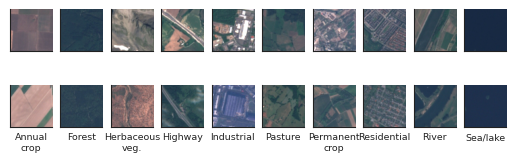

In [3]:
VISION = REPO + 'data/raw/vision' if os.path.isdir(REPO + 'data') else 'vision'
os.makedirs(VISION, exist_ok=True)
import torch, torch.nn.functional as F, torchvision
from PIL import Image
torchvision.datasets.EuroSAT(VISION, download=True)
root = os.path.join(VISION, 'eurosat', '2750')
DIRS = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
NAMES = ['Annual crop', 'Forest', 'Herbaceous veg.', 'Highway', 'Industrial', 'Pasture', 'Permanent crop', 'Residential', 'River', 'Sea/lake']
rs = np.random.RandomState(20261108); n_all = 0
fig, axes = plt.subplots(2, 10, figsize=(6.4, 1.8))
for c, d in enumerate(DIRS):
    files = sorted(f for f in os.listdir(os.path.join(root, d)) if f.endswith('.jpg')); n_all += len(files)
    tr = np.sort(rs.permutation(len(files))[:int(0.6 * len(files))])
    for r in range(2):
        axes[r, c].imshow(Image.open(os.path.join(root, d, files[tr[r]]))); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[1, c].set_xlabel(NAMES[c].replace(' ', '\n', 1), fontsize=6.8)
show('eurosat.n', 'tiles', n_all)
fig.savefig('eurosat_samples.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()